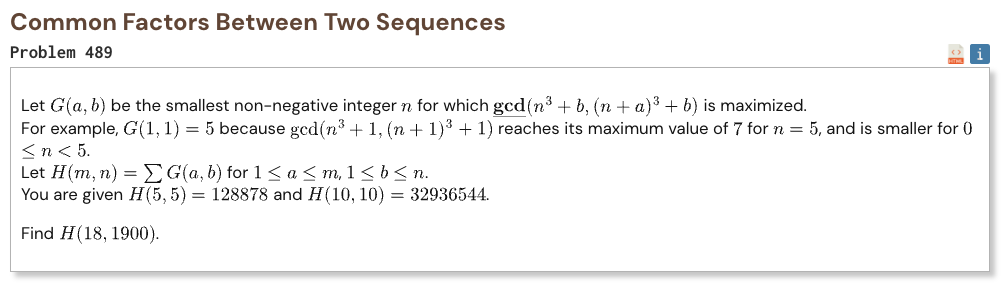

## Initial approach

- any common factor of the two cubic expressions must come from a much smaller fixed number depending only on a and b
- factor that number to find the only primes that can contribute to the maximum gcd
- for each prime, find the residue classes where both cubic expressions are divisible by that prime
- lift those residues to higher prime powers as long as both expressions remain divisible
- combine the best residue classes from different primes with the Chinese remainder theorem
- choose the smallest combined residue to get G for each pair
- sum these values for all required a and b

In [1]:
%%time

from math import isqrt

MAX_A = 18
MAX_B = 1900

def sieve_primes(limit):
    sieve = bytearray(b"\x01") * (limit + 1)
    sieve[0:2] = b"\x00\x00"

    for p in range(2, isqrt(limit) + 1):
        if sieve[p]:
            sieve[p * p:limit + 1:p] = b"\x00" * (
                (limit - p * p) // p + 1
            )

    return [
        i
        for i in range(2, limit + 1)
        if sieve[i]
    ]

primes = sieve_primes(200000)

def factorize(n):
    factors = []

    for p in primes:
        if p * p > n:
            break

        if n % p == 0:
            exponent = 0

            while n % p == 0:
                n //= p
                exponent += 1

            factors.append([p, exponent])

    if n > 1:
        factors.append([n, 1])

    return factors

def merge_factor(factors, p, exponent):
    for item in factors:
        if item[0] == p:
            item[1] += exponent
            return

    factors.append([p, exponent])

def is_root(n, a, b, mod):
    return (
        (n * n * n + b) % mod == 0
        and ((n + a) ** 3 + b) % mod == 0
    )

def roots_mod_prime(p, a, b):
    if p <= 5 or a % p == 0:
        return [
            n
            for n in range(p)
            if is_root(n, a, b, p)
        ]

    inverse = pow(2 * a * a, -1, p)

    n = (
        -(a**3 + 3 * b) * inverse
    ) % p

    if is_root(n, a, b, p):
        return [n]

    return []

def lift_prime_power(p, exponent, a, b):
    roots = roots_mod_prime(p, a, b)

    if not roots:
        return 1, [0]

    modulus = p

    for _ in range(1, exponent):
        next_modulus = modulus * p
        next_roots = []

        for root in roots:
            for digit in range(p):
                candidate = root + digit * modulus

                if is_root(
                    candidate,
                    a,
                    b,
                    next_modulus
                ):
                    next_roots.append(candidate)

        if not next_roots:
            break

        roots = next_roots
        modulus = next_modulus

    return modulus, roots

def crt(x, mod_x, y, mod_y):
    inverse = pow(mod_x, -1, mod_y)

    multiplier = (
        (y - x) * inverse
    ) % mod_y

    return x + mod_x * multiplier

def G(a, b):
    value = a**6 + 27 * b * b
    factors = factorize(value)

    for p, exponent in factorize(a):
        merge_factor(
            factors,
            p,
            3 * exponent
        )

    blocks = []

    for p, exponent in factors:
        modulus, roots = lift_prime_power(
            p,
            exponent,
            a,
            b
        )

        if modulus > 1:
            blocks.append(
                (modulus, roots)
            )

    if not blocks:
        return 0

    blocks.sort(
        key=lambda item: len(item[1])
    )

    modulus = 1
    residues = [0]

    for next_modulus, next_roots in blocks:
        next_residues = []

        for residue in residues:
            for root in next_roots:
                next_residues.append(
                    crt(
                        residue,
                        modulus,
                        root,
                        next_modulus
                    )
                )

        modulus *= next_modulus
        residues = next_residues

    return min(residues)

result = 0

for a in range(1, MAX_A + 1):
    for b in range(1, MAX_B + 1):
        result += G(a, b)

print("Result:", result)

Result: 1791954757162
CPU times: user 391 ms, sys: 1.1 ms, total: 392 ms
Wall time: 392 ms
